# NYC yellow taxi trips: cleaning checks and EDA

June to August 2025 TLC yellow taxi records. Run `scripts/download_data.py` and `scripts/clean_trips.py` first; this notebook reads the raw files and the cleaned parquet.

In [1]:
import duckdb, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
con = duckdb.connect()
raw = f"read_parquet('{ROOT}/data/raw/yellow_tripdata_2025-*.parquet')"
clean = f"read_parquet('{ROOT}/data/processed/trips_clean.parquet')"

## 1. Raw row counts per file

In [2]:
con.sql(f"SELECT month(tpep_pickup_datetime) AS m, count(*) AS rows FROM {raw} GROUP BY 1 ORDER BY 1").df()

,m,rows
0,1,2
1,5,20
2,6,4322946
3,7,3898971
4,8,3574074
5,9,1


## 2. What looks wrong in the raw data

Negative fares (refunds/voids), zero-distance trips, trips with dropoff before pickup, and multi-day durations.

In [3]:
con.sql(f'''
SELECT
  count(*) AS rows,
  sum(CASE WHEN fare_amount < 0 THEN 1 ELSE 0 END) AS negative_fare,
  sum(CASE WHEN fare_amount BETWEEN 0 AND 2.99 THEN 1 ELSE 0 END) AS fare_under_3,
  sum(CASE WHEN trip_distance = 0 THEN 1 ELSE 0 END) AS zero_distance,
  sum(CASE WHEN tpep_dropoff_datetime <= tpep_pickup_datetime THEN 1 ELSE 0 END) AS non_positive_duration,
  sum(CASE WHEN date_diff('hour', tpep_pickup_datetime, tpep_dropoff_datetime) > 3 THEN 1 ELSE 0 END) AS over_3h,
  sum(CASE WHEN passenger_count IS NULL THEN 1 ELSE 0 END) AS null_passengers,
  sum(CASE WHEN RatecodeID = 99 THEN 1 ELSE 0 END) AS ratecode_99
FROM {raw}''').df().T

,0
rows,11796014.0
negative_fare,783844.0
fare_under_3,52573.0
zero_distance,363854.0
non_positive_duration,172480.0
over_3h,3629.0
null_passengers,3137935.0
ratecode_99,173071.0


## 3. Cleaning log

Rules are applied in order, so each row is counted against the first rule it fails.

In [4]:
log = pd.read_csv(ROOT / 'data/processed/cleaning_log.csv'); log

,step,rows_remaining,rows_dropped,pct_of_raw_remaining
0,raw rows (3 monthly files),11796014,0,100.00
1,pickup inside study window (Jun-Aug 2025),11795991,23,100.00
2,valid pickup/dropoff zone (1-263),11698973,97018,99.18
3,duration between 1 and 180 min,11389892,309081,96.56
4,distance between 0.1 and 100 miles,11061518,328374,93.77
5,fare between $3 and $500 (meter drop is $3),10330580,730938,87.58
6,"non-negative tip/tolls/extras, total >= fare",10330390,190,87.58
7,average speed under 70 mph,10329605,785,87.57
8,passenger count missing or 1-6,10272514,57091,87.08
9,rate code missing or a valid TLC code,10101536,170978,85.64


In [5]:
print(f"kept {log.rows_remaining.iloc[-1]:,} of {log.rows_remaining.iloc[0]:,} rows ({log.pct_of_raw_remaining.iloc[-1]}%)")

kept 10,101,536 of 11,796,014 rows (85.64%)


## 4. Distributions after cleaning

In [6]:
s = con.sql(f"SELECT trip_distance, duration_min, fare_amount, tip_amount FROM {clean} USING SAMPLE 200000 ROWS").df()
s.describe().round(2)

,trip_distance,duration_min,fare_amount,tip_amount
count,200000.00,200000.00,200000.00,200000.00
mean,3.56,16.69,19.92,2.98
std,4.19,12.55,16.09,3.88
min,0.10,1.00,3.00,0.00
25%,1.14,8.32,10.00,0.00
50%,1.98,13.45,14.72,2.28
75%,3.91,21.05,23.30,4.04
max,42.41,175.23,300.00,130.00


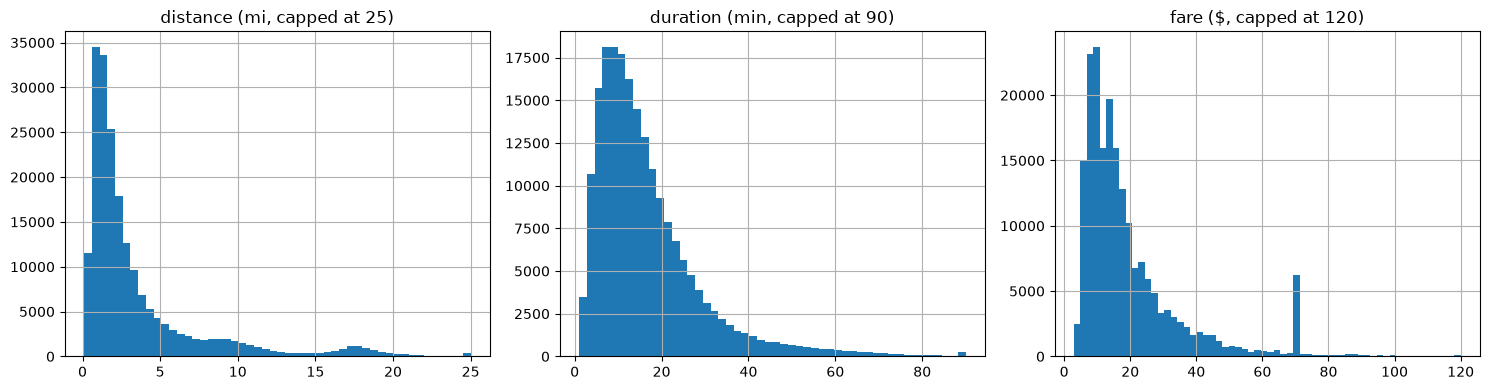

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
s.trip_distance.clip(upper=25).hist(bins=50, ax=ax[0]); ax[0].set_title('distance (mi, capped at 25)')
s.duration_min.clip(upper=90).hist(bins=50, ax=ax[1]); ax[1].set_title('duration (min, capped at 90)')
s.fare_amount.clip(upper=120).hist(bins=60, ax=ax[2]); ax[2].set_title('fare ($, capped at 120)')
plt.tight_layout()

The fare histogram has a spike near $70: that is the flat JFK-Manhattan fare (rate code 2).

In [8]:
con.sql(f"SELECT ratecode_id, count(*) AS trips, round(median(fare_amount),2) AS median_fare FROM {clean} GROUP BY 1 ORDER BY 2 DESC").df()

,ratecode_id,trips,median_fare
0,1,7428238,12.80
1,<NA>,2293948,19.44
2,2,298346,70.00
3,5,50612,65.65
4,3,27280,83.20
5,4,3111,113.60
6,6,1,3.50


## 5. Demand by hour

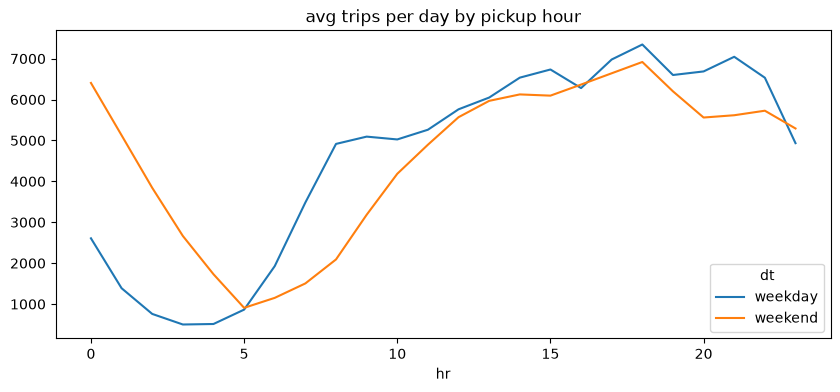

In [9]:
h = con.sql(f"SELECT hour(pickup_ts) AS hr, CASE WHEN isodow(pickup_ts) IN (6,7) THEN 'weekend' ELSE 'weekday' END AS dt, count(*) AS trips, count(DISTINCT CAST(pickup_ts AS DATE)) AS days FROM {clean} GROUP BY ALL").df()
h['per_day'] = h.trips / h.days
h.pivot(index='hr', columns='dt', values='per_day').plot(figsize=(10, 4), title='avg trips per day by pickup hour');

## 6. Payment mix and tips

Cash tips are not captured by the meter, so recorded tip rates only mean something for card trips. Payment type 0 (flex fare / not recorded) is about a fifth of trips and has almost no recorded tips.

In [10]:
con.sql(f"SELECT payment_type, count(*) AS trips, round(100*sum(tip_amount)/sum(fare_amount),1) AS tip_pct FROM {clean} GROUP BY 1 ORDER BY 2 DESC").df()

,payment_type,trips,tip_pct
0,1,6621520,22.9
1,0,2293948,1.5
2,2,1006279,0.0
3,4,142223,0.0
4,3,37565,0.1
5,5,1,0.0


## 7. Monthly trend

Volume fell month over month across the summer; the raw files shrink the same way (4.32M, 3.90M, 3.57M rows), so this is not a cleaning artefact.

In [11]:
con.sql(f"SELECT month(pickup_ts) AS m, count(*) AS trips, round(avg(total_amount),2) AS avg_total FROM {clean} GROUP BY 1 ORDER BY 1").df()

,m,trips,avg_total
0,6,3737385,28.93
1,7,3361023,28.42
2,8,3003128,28.50
